In [1]:
from pathlib import Path
import json
import os
import sys
import zipfile

# Windows setup from the lab sheet; set before importing NumPy or PyTorch.
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

try:
    import torch
    from torch import nn
except ModuleNotFoundError as error:
    if error.name != "torch":
        raise
    raise ModuleNotFoundError(
        "PyTorch is missing. Run the install cell below, "
        "restart the kernel, and rerun Cell 1."
    ) from error

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
    torch.set_num_threads(min(4, os.cpu_count() or 1))

here = Path.cwd()
PROJECT_ROOT = next(
    (folder for folder in (here, *here.parents)
     if (folder / "all_datasets").is_dir()),
    Path(r"C:\Users\Hp\OneDrive\Desktop\Documents\UTP-MACHINE-LEARNING"),
)

archive_path = (
    PROJECT_ROOT / "all_datasets" /
    "optical_recognition_handwritten_digits.zip"
)

MODELS = PROJECT_ROOT / "models"

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("Digits ZIP:", archive_path)

if not archive_path.is_file():
    raise FileNotFoundError(f"Put the original Lab 4 digits ZIP at: {archive_path}")

MODELS.mkdir(exist_ok=True)
print("Dataset found.")

ModuleNotFoundError: PyTorch is missing. Run the install cell below, restart the kernel, and rerun Cell 1.

In [2]:
%pip install torch --index-url https://download.pytorch.org/whl/cpu

Looking in indexes: https://download.pytorch.org/whl/cpu
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement torch (from versions: none)
ERROR: No matching distribution found for torch


In [4]:
%pip install torch --index-url https://pypi.org/simple

Note: you may need to restart the kernel to use updated packages.


In [1]:
from pathlib import Path
import json
import os
import sys
import zipfile

# Windows setup from the lab sheet; set before importing NumPy or PyTorch.
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

try:
    import torch
    from torch import nn
except ModuleNotFoundError as error:
    if error.name != "torch":
        raise
    raise ModuleNotFoundError(
        "PyTorch is missing. Run the install cell below, "
        "restart the kernel, and rerun Cell 1."
    ) from error

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
    torch.set_num_threads(min(4, os.cpu_count() or 1))

here = Path.cwd()
PROJECT_ROOT = next(
    (folder for folder in (here, *here.parents)
     if (folder / "all_datasets").is_dir()),
    Path(r"C:\Users\Hp\OneDrive\Desktop\Documents\UTP-MACHINE-LEARNING"),
)

archive_path = (
    PROJECT_ROOT / "all_datasets" /
    "optical_recognition_handwritten_digits.zip"
)

MODELS = PROJECT_ROOT / "models"

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("Digits ZIP:", archive_path)

if not archive_path.is_file():
    raise FileNotFoundError(f"Put the original Lab 4 digits ZIP at: {archive_path}")

MODELS.mkdir(exist_ok=True)
print("Dataset found.")

Python: 3.14.6
PyTorch: 2.15.0+cpu
Device: cpu
Digits ZIP: C:\Users\Hp\OneDrive\Desktop\Documents\UTP-MACHINE-LEARNING\all_datasets\optical_recognition_handwritten_digits.zip
Dataset found.


C:\Users\Hp\AppData\Local\Temp\ipykernel_23420\1673036696.py:18: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  y = torch.from_numpy(labels)


Fit: (2868, 1, 8, 8)
Validation: (955, 1, 8, 8)
Official test: (1797, 1, 8, 8)


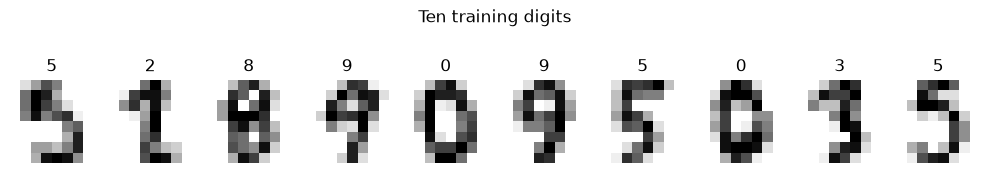

In [2]:
columns = [f"pixel_{i}" for i in range(64)] + ["label"]

with zipfile.ZipFile(archive_path) as archive:
    members = {Path(name).name: name for name in archive.namelist()}

    def read_split(filename):
        with archive.open(members[filename]) as file:
            return pd.read_csv(file, header=None, names=columns)

    train = read_split("optdigits.tra")
    test = read_split("optdigits.tes")


def to_tensors(frame):
    pixels = frame.drop(columns="label").to_numpy(dtype=np.float32)
    labels = frame["label"].to_numpy(dtype=np.int64)
    X = torch.from_numpy(pixels).reshape(-1, 1, 8, 8) / 16.0
    y = torch.from_numpy(labels)
    return X.to(DEVICE), y.to(DEVICE)


X_dev, y_dev = to_tensors(train)
X_test, y_test = to_tensors(test)

perm = torch.randperm(
    len(X_dev), generator=torch.Generator().manual_seed(42)
).to(DEVICE)

n_val = len(X_dev) // 4
val_idx, fit_idx = perm[:n_val], perm[n_val:]
X_fit, y_fit = X_dev[fit_idx], y_dev[fit_idx]
X_val, y_val = X_dev[val_idx], y_dev[val_idx]

print("Fit:", tuple(X_fit.shape))
print("Validation:", tuple(X_val.shape))
print("Official test:", tuple(X_test.shape))

fig, axes = plt.subplots(1, 10, figsize=(10, 2))
for ax, digit, label in zip(axes, X_fit[:10], y_fit[:10]):
    ax.imshow(digit[0].cpu(), cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(str(label.item()))
    ax.axis("off")

fig.suptitle("Ten training digits")
plt.tight_layout()
plt.show()

In [3]:
def make_mlp():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(64, 128),
        nn.ReLU(),
        nn.Linear(128, 10),
    )


def make_cnn():
    return nn.Sequential(
        nn.Conv2d(1, 16, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(16, 32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(32 * 2 * 2, 64),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(64, 10),
    )


@torch.no_grad()
def predict(model, X):
    model.eval()
    return model(X).argmax(dim=1)


def accuracy(model, X, y):
    return (predict(model, X) == y).float().mean().item()


def train_classifier(make_model, epochs, lr=0.003, batch_size=32, seed=42):
    torch.manual_seed(seed)
    model = make_model().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    history = {"train": [], "validation": []}
    best_val, best_epoch, best_weights = -1.0, 0, None

    for epoch in range(1, epochs + 1):
        model.train()
        order = torch.randperm(len(X_fit), device=DEVICE)

        for batch in order.split(batch_size):
            optimizer.zero_grad()
            logits = model(X_fit[batch])
            loss = loss_fn(logits, y_fit[batch])
            loss.backward()
            optimizer.step()

        train_acc = accuracy(model, X_fit, y_fit)
        val_acc = accuracy(model, X_val, y_val)
        history["train"].append(train_acc)
        history["validation"].append(val_acc)

        if val_acc > best_val:
            best_val, best_epoch = val_acc, epoch
            best_weights = {
                name: tensor.detach().cpu().clone()
                for name, tensor in model.state_dict().items()
            }

        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            print(f"Epoch {epoch:2d}/{epochs}: "
                  f"train={train_acc:.4f}, validation={val_acc:.4f}")

    model.load_state_dict(best_weights)
    model.eval()
    print(f"Selected epoch: {best_epoch}; validation accuracy: {best_val:.4f}")
    return model, history, best_epoch


def plot_history(history, best_epoch, title):
    epochs = range(1, len(history["train"]) + 1)

    plt.figure(figsize=(7, 4))
    plt.plot(epochs, history["train"], label="Training")
    plt.plot(epochs, history["validation"], label="Validation")
    plt.axvline(best_epoch, color="gray", linestyle="--",
                label=f"Selected epoch: {best_epoch}")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=64, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)
Trainable parameters: 9610
Epoch  1/20: train=0.9268, validation=0.9089
Epoch  5/20: train=0.9801, validation=0.9634
Epoch 10/20: train=0.9878, validation=0.9675
Epoch 15/20: train=0.9899, validation=0.9749
Epoch 20/20: train=0.9990, validation=0.9728
Selected epoch: 12; validation accuracy: 0.9759


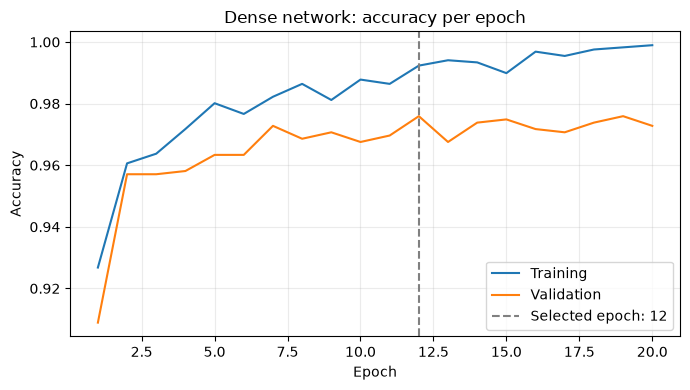

In [4]:
print(make_mlp())
print("Trainable parameters:", sum(p.numel() for p in make_mlp().parameters()))

mlp, mlp_history, mlp_epoch = train_classifier(make_mlp, epochs=20)
plot_history(mlp_history, mlp_epoch, "Dense network: accuracy per epoch")

Trainable parameters: 13706
Input: (1, 1, 8, 8)
Conv2d       -> (1, 16, 8, 8)
MaxPool2d    -> (1, 16, 4, 4)
Conv2d       -> (1, 32, 4, 4)
MaxPool2d    -> (1, 32, 2, 2)
Flatten      -> (1, 128)
Linear       -> (1, 64)
Linear       -> (1, 10)
Epoch  1/20: train=0.8919, validation=0.8733
Epoch  5/20: train=0.9798, validation=0.9665
Epoch 10/20: train=0.9899, validation=0.9686
Epoch 15/20: train=0.9976, validation=0.9832
Epoch 20/20: train=0.9955, validation=0.9791
Selected epoch: 15; validation accuracy: 0.9832


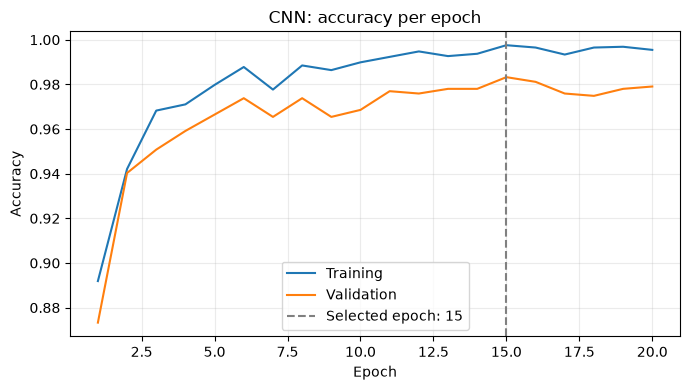

In [5]:
shape_model = make_cnn().to(DEVICE).eval()
print("Trainable parameters:", sum(p.numel() for p in shape_model.parameters()))

with torch.no_grad():
    sample = X_fit[:1]
    print("Input:", tuple(sample.shape))
    for layer in shape_model:
        sample = layer(sample)
        if isinstance(layer, (nn.Conv2d, nn.MaxPool2d, nn.Flatten, nn.Linear)):
            print(f"{type(layer).__name__:12s} -> {tuple(sample.shape)}")

cnn, cnn_history, cnn_epoch = train_classifier(make_cnn, epochs=20)
plot_history(cnn_history, cnn_epoch, "CNN: accuracy per epoch")

Full CNN, 40 epochs
Epoch  1/40: train=0.8919, validation=0.8733
Epoch  5/40: train=0.9798, validation=0.9665
Epoch 10/40: train=0.9899, validation=0.9686
Epoch 15/40: train=0.9976, validation=0.9832
Epoch 20/40: train=0.9955, validation=0.9791
Epoch 25/40: train=0.9990, validation=0.9738
Epoch 30/40: train=1.0000, validation=0.9801
Epoch 35/40: train=0.9969, validation=0.9780
Epoch 40/40: train=0.9983, validation=0.9801
Selected epoch: 38; validation accuracy: 0.9843

CNN without the second block, 40 epochs
Epoch  1/40: train=0.8919, validation=0.8869
Epoch  5/40: train=0.9745, validation=0.9696
Epoch 10/40: train=0.9857, validation=0.9654
Epoch 15/40: train=0.9944, validation=0.9812
Epoch 20/40: train=0.9979, validation=0.9770
Epoch 25/40: train=0.9993, validation=0.9822
Epoch 30/40: train=0.9997, validation=0.9864
Epoch 35/40: train=0.9990, validation=0.9801
Epoch 40/40: train=0.9955, validation=0.9864
Selected epoch: 21; validation accuracy: 0.9864


,Model,Epoch budget,Last validation accuracy,Best epoch,Best validation accuracy
0,Full CNN,5,0.9665,5,0.9665
1,Full CNN,40,0.9801,38,0.9843
2,CNN without second block,40,0.9864,21,0.9864


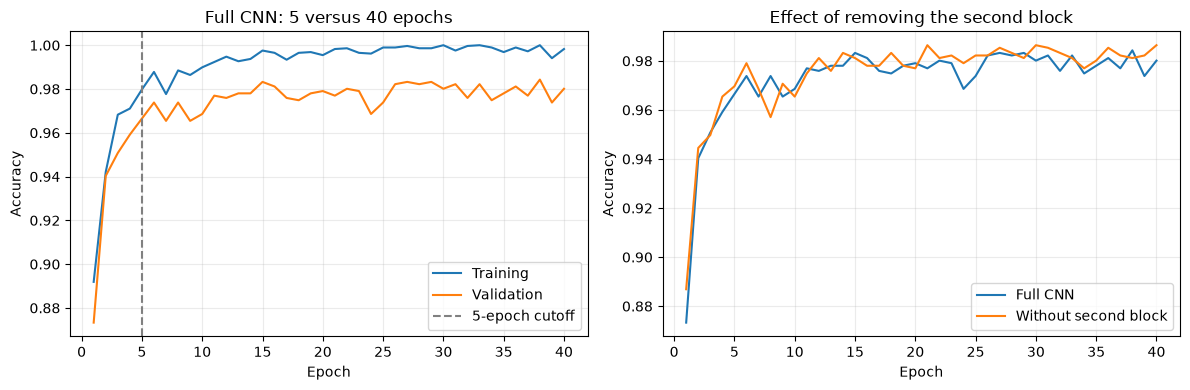

In [6]:
def make_shallow_cnn():
    return nn.Sequential(
        nn.Conv2d(1, 16, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(16 * 4 * 4, 64),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(64, 10),
    )


print("Full CNN, 40 epochs")
_, full40_history, full40_epoch = train_classifier(make_cnn, epochs=40)

print("\nCNN without the second block, 40 epochs")
_, shallow_history, shallow_epoch = train_classifier(make_shallow_cnn, epochs=40)

full_val = full40_history["validation"]
shallow_val = shallow_history["validation"]
best_first_five = int(np.argmax(full_val[:5])) + 1

extra_results = pd.DataFrame([
    ["Full CNN", 5, full_val[4], best_first_five, max(full_val[:5])],
    ["Full CNN", 40, full_val[-1], full40_epoch, max(full_val)],
    ["CNN without second block", 40, shallow_val[-1], shallow_epoch, max(shallow_val)],
], columns=[
    "Model", "Epoch budget", "Last validation accuracy",
    "Best epoch", "Best validation accuracy",
])

display(extra_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = np.arange(1, 41)

axes[0].plot(epochs, full40_history["train"], label="Training")
axes[0].plot(epochs, full_val, label="Validation")
axes[0].axvline(5, linestyle="--", color="gray", label="5-epoch cutoff")
axes[0].set_title("Full CNN: 5 versus 40 epochs")

axes[1].plot(epochs, full_val, label="Full CNN")
axes[1].plot(epochs, shallow_val, label="Without second block")
axes[1].set_title("Effect of removing the second block")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.legend()
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

Official test digits: 1797


,Model,Selected epoch,Official test accuracy
0,PCA + logistic regression (Lab 4),NaN,0.9477
1,Dense network,12.0,0.9555
2,CNN,15.0,0.9666


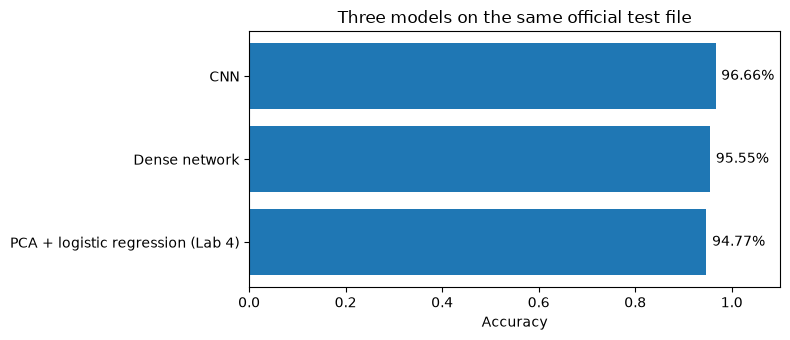

In [7]:
mlp_pred = predict(mlp, X_test)
cnn_pred = predict(cnn, X_test)

test_scores = pd.DataFrame([
    ["PCA + logistic regression (Lab 4)", None, 0.9477],
    ["Dense network", mlp_epoch, (mlp_pred == y_test).float().mean().item()],
    ["CNN", cnn_epoch, (cnn_pred == y_test).float().mean().item()],
], columns=["Model", "Selected epoch", "Official test accuracy"])

print("Official test digits:", len(y_test))
display(test_scores.round(4))

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh(test_scores["Model"], test_scores["Official test accuracy"])
ax.bar_label(
    bars,
    labels=[f"{score:.2%}" for score in test_scores["Official test accuracy"]],
    padding=4,
)
ax.set_xlim(0, 1.10)
ax.set_xlabel("Accuracy")
ax.set_title("Three models on the same official test file")
plt.tight_layout()
plt.show()

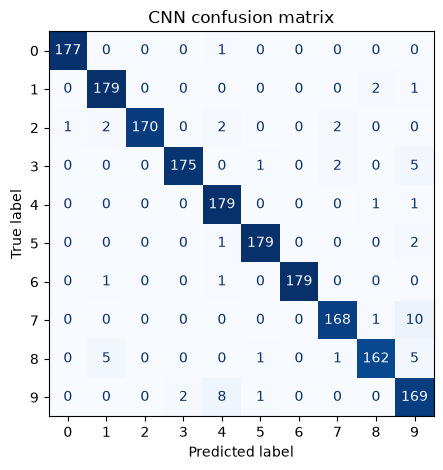

Total mistakes: 60
Most frequent confusions (true -> predicted):
7 -> 9: 10
9 -> 4: 8
8 -> 9: 5
8 -> 1: 5
3 -> 9: 5


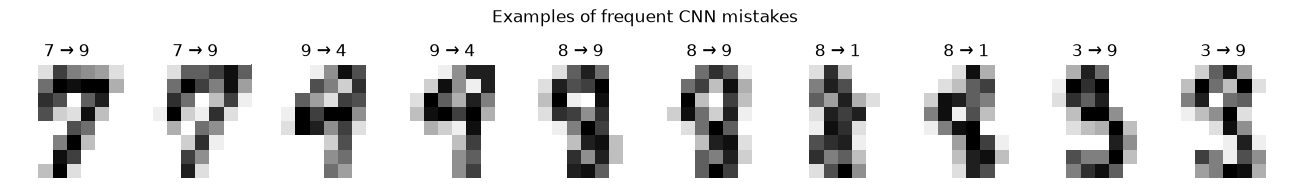

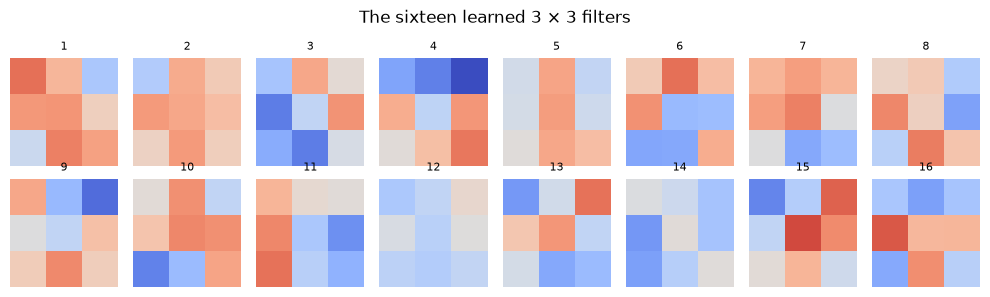

In [8]:
true = y_test.cpu().numpy()
pred = cnn_pred.cpu().numpy()

cm = confusion_matrix(true, pred, labels=np.arange(10))
ConfusionMatrixDisplay(cm, display_labels=np.arange(10)).plot(
    cmap="Blues", colorbar=False
)
plt.title("CNN confusion matrix")
plt.tight_layout()
plt.show()

pairs = sorted(
    [(int(cm[a, b]), a, b)
     for a in range(10) for b in range(10)
     if a != b and cm[a, b] > 0],
    reverse=True,
)

print("Total mistakes:", int((true != pred).sum()))

if pairs:
    print("Most frequent confusions (true -> predicted):")
    for count, actual, predicted in pairs[:5]:
        print(f"{actual} -> {predicted}: {count}")

    examples = [
        int(index)
        for _, actual, predicted in pairs[:5]
        for index in np.flatnonzero((true == actual) & (pred == predicted))[:2]
    ]

    fig, axes = plt.subplots(
        1, len(examples), figsize=(1.3 * len(examples), 2), squeeze=False
    )
    for ax, index in zip(axes.ravel(), examples):
        ax.imshow(X_test[index, 0].cpu(), cmap="gray_r", vmin=0, vmax=1)
        ax.set_title(f"{true[index]} → {pred[index]}")
        ax.axis("off")
    fig.suptitle("Examples of frequent CNN mistakes")
    plt.tight_layout()
    plt.show()

filters = cnn[0].weight.detach().cpu().numpy()[:, 0]
limit = float(np.abs(filters).max())

fig, axes = plt.subplots(2, 8, figsize=(10, 3))
for number, (ax, kernel) in enumerate(zip(axes.flat, filters), start=1):
    ax.imshow(kernel, cmap="coolwarm", vmin=-limit, vmax=limit)
    ax.set_title(str(number), fontsize=8)
    ax.axis("off")

fig.suptitle("The sixteen learned 3 × 3 filters")
plt.tight_layout()
plt.show()

In [9]:
weights_path = MODELS / "digits_cnn.pt"
card_path = MODELS / "digits_cnn_card.json"

torch.save(cnn.state_dict(), weights_path)

card = {
    "task": "Classify 8x8 handwritten digits (0-9)",
    "input": "Float tensor of shape (n, 1, 8, 8), pixel values divided by 16",
    "architecture": "make_cnn() in Lab 7: conv16-pool-conv32-pool-dense64-dense10",
    "training": {
        "epoch_budget": 20,
        "selected_epoch": cnn_epoch,
        "checkpoint_rule": "Earliest epoch with highest validation accuracy",
        "learning_rate": 0.003,
        "batch_size": 32,
        "seed": 42,
    },
    "validation_accuracy": round(cnn_history["validation"][cnn_epoch - 1], 4),
    "official_test_accuracy": round(float(test_scores.iloc[2]["Official test accuracy"]), 4),
    "torch_version": str(torch.__version__),
    "trained_on": str(DEVICE),
}

card_path.write_text(json.dumps(card, indent=2) + "\n", encoding="utf-8")

restored = make_cnn().to(DEVICE)
restored.load_state_dict(
    torch.load(weights_path, map_location=DEVICE, weights_only=True)
)

same = torch.equal(predict(restored, X_test), cnn_pred)

print(f"Saved {weights_path.name}: {weights_path.stat().st_size / 1024:.1f} KB")
print("Model card saved:", card_path.is_file())
print("Reload reproduces all official test predictions:", same)
assert same, "The reloaded CNN did not match the original predictions."

Saved digits_cnn.pt: 57.1 KB
Model card saved: True
Reload reproduces all official test predictions: True


## Data Preparation and Training

Each handwritten digit was reshaped into a single-channel 8 × 8 image, and pixel values were divided by 16 to scale them to [0, 1]. One quarter of the official training file was reserved for validation. The official test file was kept separate until final evaluation.

The dense network flattened each image into 64 inputs. The CNN used convolution filters to learn local patterns while preserving spatial structure in its early layers. Both models used validation accuracy to select a checkpoint from their 20-epoch training runs.

## Official Test Results

| Model | Selected epoch | Test accuracy |
|---|---:|---:|
| PCA + logistic regression (Lab 4) | — | 94.77% |
| Dense neural network | 12 | 95.55% |
| CNN | 15 | 96.66% |

The CNN performed best on the same 1,797 official test digits. It improved on the dense network by **1.11 percentage points** and on the Lab 4 baseline by **1.89 percentage points**. It classified **1,737 of 1,797** images correctly. One possible reason for the improvement is that convolution filters can recognize local stroke patterns in different parts of an image.

## Try It Yourself: Training Duration and the Second Convolution Block

| Model | Epoch budget | Accuracy at last epoch | Best epoch | Best validation accuracy |
|---|---:|---:|---:|---:|
| Full CNN | 5 | 96.65% | 5 | 96.65% |
| Full CNN | 40 | 98.01% | 38 | 98.43% |
| CNN without the second block | 40 | 98.64% | 21 | 98.64% |

Training the full CNN beyond five epochs raised its best validation accuracy from **96.65% to 98.43%**. However, training accuracy approached 100% while validation accuracy leveled off and fluctuated. Epoch 38 performed better on validation than epoch 40, showing why it is useful to keep the best checkpoint instead of always using the last one.

Removing the second convolution, ReLU, and pooling block gave a slightly higher best validation accuracy: **98.64% versus 98.43%**, a difference of **0.21 percentage points**. In this run, the second block did not improve peak validation accuracy. The gap was small and came from one training run, so it does not establish that the shallower model is generally better. These extra experiments used validation data only; the official test results above came from the main 20-epoch runs.

## CNN Errors and Learned Filters

The CNN made **60 mistakes**. The most frequent confusions were:

| True digit → predicted digit | Count |
|---|---:|
| 7 → 9 | 10 |
| 9 → 4 | 8 |
| 8 → 9 | 5 |
| 8 → 1 | 5 |
| 3 → 9 | 5 |

In some examples, the top stroke of a 7 almost forms a loop, and some 9s have an angular shape resembling a 4. These similarities are visible in the 8 × 8 images and may help explain individual errors. The confusion matrix shows which errors occurred, while the images help suggest why.

The first convolutional layer learned **sixteen 3 × 3 filters**. Contrasting positive and negative weights can make a filter respond to local brightness changes, such as stroke edges. The same filter is applied across different image locations.

## Saving and Reloading the CNN

The CNN weights were saved as `models/digits_cnn.pt` (**57.1 KB**), and the model card was saved as `models/digits_cnn_card.json`. The card records the expected input format, architecture, training settings, and accuracy. Loading the weights into a fresh copy of the same architecture reproduced **all official test predictions**, confirming that the saved model can be used without retraining.